# Métricas · xgboost · Optuna, derivadas, calibração e limiar

    Relatório de treino e validação. TEST permanece reservado. Os gráficos leem artefatos;
    executar o notebook não repete treinamento. Para nova busca, usar scripts/train_advanced.py.

## 1. Contrato, blocos e mudança de protocolo

    Machine failure=1 é positivo. Usam-se cinco sensores e Type, sem IDs ou modos de falha.
    Desenvolvimento: 8.000 registros, sendo FIT_SEARCH 1–4.800 (221 falhas), CALIBRATION
    4.801–5.600 (27), THRESHOLD 5.601–6.400 (17) e VALIDAÇÃO 6.401–8.000 (35).
    TEST 8.001–10.000 segue reservado. UDI é ordem, não tempo comprovado; gap=0.

    Optuna usa três folds crescentes somente em FIT_SEARCH; critério AUPRC trapezoidal
    no XGBoost e AP no RF. Sem pruning, para avaliar todos os folds de regimes distintos.
    O modelo é reajustado em 4.800, congelado e calibrado por sigmoid em outro bloco;
    depois o limiar é escolhido por F1 em um terceiro bloco, com o modelo calibrado congelado.
    Não há refit após escolher o limiar. AUPRC e AP usam predict_proba[:, 1].

    A rodada anterior ajustava 6.400 registros: a busca/CV e quantidade de ajuste agora
    são diferentes. A validação externa ao ajuste é a mesma, mas já reutilizada no
    desenvolvimento; não é confirmação independente. Mudanças não isolam um único efeito.

In [1]:
from pathlib import Path
import sys
import json
from IPython.display import display, Markdown

ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / 'configs/advanced.json').is_file())
sys.path.insert(0, str(ROOT / 'src'))
from predictive_maintenance.training import latest_run
from predictive_maintenance.advanced_reporting import AdvancedReport
from predictive_maintenance.presentation import readable_table, readable_parameters, translate_text

def show(text):
    display(Markdown(translate_text(text)))

MODEL_NAME = 'xgboost'
RUN_ID = None  # Informe uma execução para revisar um snapshot específico.
run = ROOT / 'reports/experiments' / RUN_ID if RUN_ID else latest_run(ROOT, MODEL_NAME)
report = AdvancedReport(ROOT, run)
manifest = report.manifest
assert manifest['experiment_type'] == 'OPTUNA_FEATURES_CALIBRATION_THRESHOLD'
assert manifest['test_evaluated'] is False
print('Execução:', manifest['run_id'])
print('Execução anterior:', manifest['previous_run'])
print('TEST avaliado:', manifest['test_evaluated'])
display(manifest['versions'])

Execução: train_xgboost_20261101T001759Z_4c8d9ea9
Execução anterior: train_xgboost_20261031T235601Z_fa7abc82
TEST avaliado: False


{'optuna': '5.0.0',
 'scikit-learn': '1.9.1',
 'xgboost': '3.4.1',
 'imbalanced-learn': '0.14.2',
 'pandas': '2.3.3',
 'numpy': '2.5.4',
 'joblib': '1.6.0'}

## 2. Variáveis derivadas e SMOTENC

    Diferença térmica = temperatura de processo − ar (K).
    Potência mecânica = torque × rpm × 2π/60 (W).
    Interação desgaste × torque (min·Nm).
    As fórmulas são determinísticas, calculadas dos sensores dentro do pipeline.
    Não usam o rótulo ou estatísticas globais. Imputação e StandardScaler são ajustados
    em cada treino, seguido de SMOTENC; Type permanece categoria até o one-hot.
    A síntese de derivados pode não preservar identidades físicas exatas.
    A disponibilidade dos sensores antes da decisão real continua uma hipótese a confirmar.

In [2]:
display(manifest['derived_features'])
display(readable_table(report.table('sampling_counts')))

['Temperature gap [K]', 'Mechanical power [W]', 'Wear torque [min Nm]']

,Origem,Não falhas antes do sampler,Falhas antes do sampler,Não falhas após sampler,Falhas após sampler,Falhas sintéticas criadas
0,Refit no bloco de busca,4.579,221,4.579,1.144,923


## 3. Optuna: orçamento, espaço e escolhido

    24 tentativas TPE por modelo × três folds = 72 fits de busca, mais refit, baseline
    e três fits da ablação. Busca sequencial com semente; folds usam dois workers,
    cada modelo usa uma thread. O espaço inclui pesos, razão/vizinhos do SMOTENC,
    número de árvores, profundidade e regularização. SMOTENC obrigatório em todas as tentativas.
    O escolhido é o melhor da busca realizada, não ótimo global. Arquivo SQLite local
    registra o estudo; CSV registra tentativas completas, inclusive parâmetros e scores.

{'common': {'sampling_strategy': [0.15, 0.25, 0.5],
  'k_neighbors': [3, 5],
  'positive_weight': [1, 3, 10]},
 'xgboost': {'n_estimators': [100, 150, 300],
  'max_depth': [2, 3, 4, 5, 6],
  'learning_rate': [0.02, 0.2],
  'min_child_weight': [1, 3, 5, 10],
  'subsample': [0.7, 0.85, 1.0],
  'colsample_bytree': [0.7, 0.85, 1.0],
  'reg_alpha': [0.0, 0.1, 1.0],
  'reg_lambda': [1.0, 3.0, 10.0]},
 'random_forest': {'n_estimators': [150, 300],
  'max_depth': [None, 6, 10, 16],
  'min_samples_leaf': [1, 2, 4, 8],
  'max_features': ['sqrt', 0.7, 1.0],
  'criterion': ['gini', 'entropy'],
  'max_samples': [0.7, 1.0]}}

Parâmetro,Descrição,Valor
sampling_strategy,Razão de falhas/não falhas após SMOTENC,0.25
k_neighbors,Vizinhos do SMOTENC,3
positive_weight,Peso da classe positiva,3
n_estimators,Número de árvores,300
max_depth,Profundidade máxima,5
learning_rate,Taxa de aprendizado,0.10304083606503335
min_child_weight,Peso mínimo de filho,1
subsample,Fração de linhas por árvore,0.85
colsample_bytree,Fração de variáveis por árvore,0.85
reg_alpha,Regularização L1,1.0


Critério: auprc


Melhor média CV: 0,6806

,Índice da tentativa,Score objetivo (CV),Duração,Fração de variáveis por árvore,Vizinhos do SMOTENC,Taxa de aprendizado,Profundidade máxima,Peso mínimo de filho,Número de árvores,Peso da classe positiva,Regularização L1,Regularização L2,Razão de falhas/não falhas após SMOTENC,Fração de linhas por árvore,Estado
0,0,"0,5486",0 days 00:00:07.398862,"0,8500",3,"0,0403",2,10,150,10,"0,1000",1,"0,2500",1,Concluída
1,1,"0,6393",0 days 00:00:01.553717,1,3,"0,0306",3,1,300,1,1,10,"0,2500","0,8500",Concluída
2,2,"0,5998",0 days 00:00:01.764034,1,3,"0,0428",5,10,300,10,"0,1000",1,"0,2500","0,8500",Concluída
3,3,"0,5994",0 days 00:00:00.847303,1,5,"0,1488",4,5,100,1,"0,1000",1,"0,5000","0,8500",Concluída
4,4,"0,5870",0 days 00:00:01.103645,"0,8500",5,"0,0225",5,3,100,10,0,1,"0,5000","0,8500",Concluída
5,5,"0,5789",0 days 00:00:01.199899,1,5,"0,0260",4,1,150,1,0,10,"0,1500","0,7000",Concluída
6,6,"0,5557",0 days 00:00:01.450424,"0,8500",5,"0,1031",4,5,150,1,"0,1000",1,"0,1500","0,7000",Concluída
7,7,"0,6525",0 days 00:00:02.609975,"0,8500",5,"0,1852",5,1,300,10,1,1,"0,2500","0,7000",Concluída
8,8,"0,6134",0 days 00:00:01.075229,"0,8500",3,"0,1553",3,10,150,10,"0,1000",10,"0,1500",1,Concluída
9,9,"0,6050",0 days 00:00:01.028839,"0,7000",5,"0,1835",2,1,100,10,0,1,"0,2500",1,Concluída


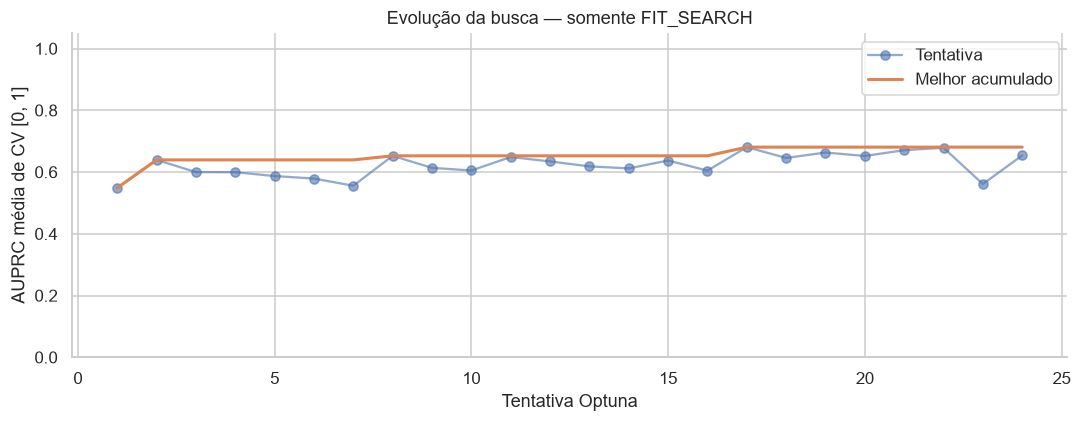

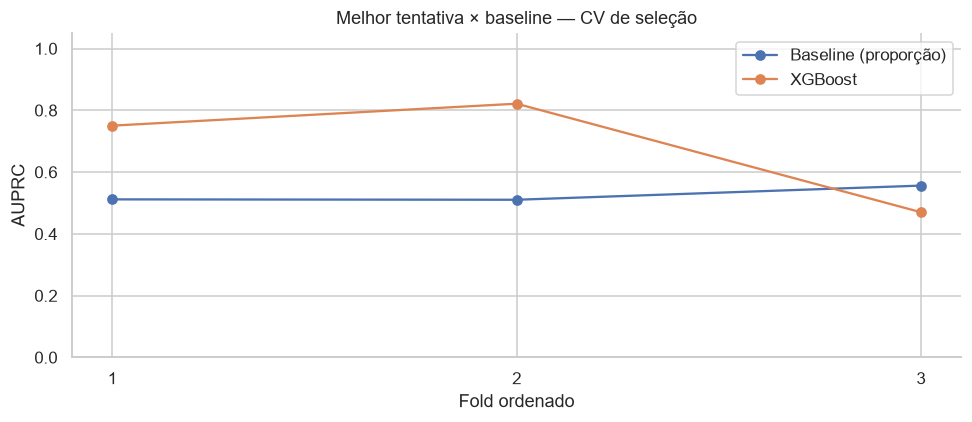

In [3]:
display(manifest['settings']['space'])
display(readable_parameters(manifest['best_params']))
print('Critério:', manifest['selection_metric'])
show(f"Melhor média CV: {manifest['best_cv_score']:.4f}")
trials = report.table('optuna_trials')
columns = [c for c in trials.columns if c in ['number','value','duration','state'] or c.startswith('params_')]
display(readable_table(trials[columns]))
report.study_figures()

## 4. Estatísticas de CV e ablação de features

    A CV do escolhido tem otimismo de seleção, sem CV aninhada. O resumo mostra
    média e desvio amostral, sem interpretar três folds como intervalo de confiança.
    A ablação remove somente as derivadas, mantendo os parâmetros escolhidos. É um
    diagnóstico pareado em CV, não comparação de dois modelos igualmente otimizados.

,Receita,Fold ordenado,Origem,Observações de treino,Observações de validação,Falhas no treino,Falhas na validação,Limiar de alerta,AP (score) — validação,AP (score) — treino,ROC-AUC (score) — validação,ROC-AUC (score) — treino,AUPRC trapezoidal (score) — validação,AUPRC trapezoidal (score) — treino,F1 (%) — validação,F1 (%) — treino,Recall (%) — validação,Recall (%) — treino,Precision (%) — validação,Precision (%) — treino,Acurácia balanceada (%) — validação,Acurácia balanceada (%) — treino
0,XGBoost,1,CV de seleção,1.200,1.200,33,28,"0,5000","0,7523","1,0000","0,9554",1,"0,7504","1,0000","55,00%","98,51%","78,57%","100,00%","42,31%","97,06%","88,01%","99,96%"
1,XGBoost,2,CV de seleção,2.400,1.200,61,25,"0,5000","0,8225",1,"0,9451",1,"0,8215",1,"66,67%","100,00%","84,00%","100,00%","55,26%","100,00%","91,28%","100,00%"
2,XGBoost,3,CV de seleção,3.600,1.200,86,135,"0,5000","0,4716",1,"0,8667",1,"0,4701",1,"31,69%","99,42%","21,48%","100,00%","60,42%","98,85%","59,85%","99,99%"
3,Baseline (proporção),1,CV do baseline,1.200,1.200,33,28,"0,5000","0,0233","0,0275","0,5000","0,5000","0,5117","0,5138","0,00%","0,00%","0,00%","0,00%","0,00%","0,00%","50,00%","50,00%"
4,Baseline (proporção),2,CV do baseline,2.400,1.200,61,25,"0,5000","0,0208","0,0254","0,5000","0,5000","0,5104","0,5127","0,00%","0,00%","0,00%","0,00%","0,00%","0,00%","50,00%","50,00%"
5,Baseline (proporção),3,CV do baseline,3.600,1.200,86,135,"0,5000","0,1125","0,0239","0,5000","0,5000","0,5563","0,5119","0,00%","0,00%","0,00%","0,00%","0,00%","0,00%","50,00%","50,00%"


,Versão,Fold ordenado,AP (score),ROC-AUC (score),AUPRC trapezoidal (score),F1 (%),Recall (%),Precision (%),Acurácia balanceada (%)
0,Sem variáveis derivadas,1,"0,5885","0,9281","0,5841","45,16%","75,00%","32,31%","85,62%"
1,Sem variáveis derivadas,2,"0,5219","0,9475","0,4980","50,79%","64,00%","42,11%","81,06%"
2,Sem variáveis derivadas,3,"0,3222","0,6640","0,3207","27,14%","20,00%","42,19%","58,26%"
3,Com variáveis derivadas,1,"0,7523","0,9554","0,7504","55,00%","78,57%","42,31%","88,01%"
4,Com variáveis derivadas,2,"0,8225","0,9451","0,8215","66,67%","84,00%","55,26%","91,28%"
5,Com variáveis derivadas,3,"0,4716","0,8667","0,4701","31,69%","21,48%","60,42%","59,85%"


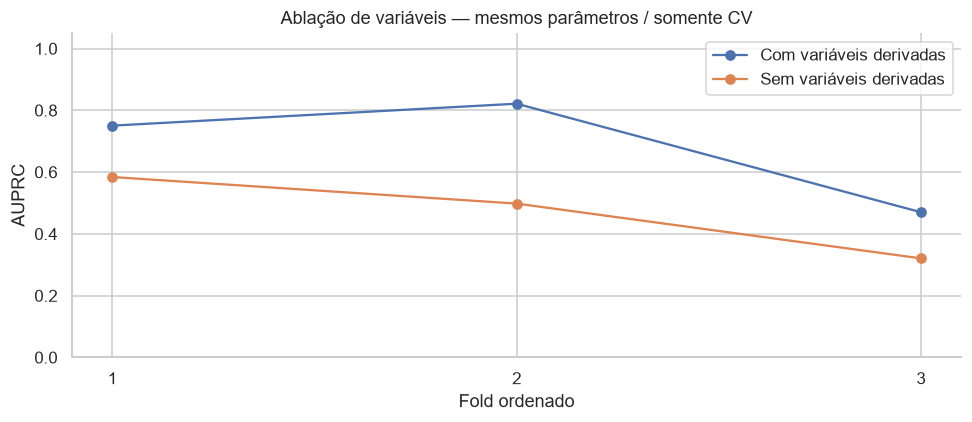

In [4]:
display(readable_table(report.table('fold_metrics')))
display(readable_table(report.summary()))
display(readable_table(report.table('feature_ablation')))
report.ablation_figure()

## 5. Calibração e ajuste de limiar

    CalibratedClassifierCV usa sigmoid e FrozenEstimator: base não reaprende com as
    800 observações de calibração. TunedThresholdClassifierCV usa cv=prefit e refit=False
    sobre o modelo calibrado congelado, somente nas outras 800 observações.
    O objetivo provisório é F1, pois custos e capacidade operacional não foram definidos.
    A grade usa scores distintos do bloco THRESHOLD e referências 0/0,5/1.
    Poucas falhas (27 e 17) limitam a estabilidade dessas duas etapas.
    Um sigmoid ajustado não comprova boa calibração no futuro.

Limiar escolhido em TRAIN: 0,81516; F1 no bloco de seleção: 80,00%

Política: F1 on disjoint THRESHOLD block; frozen calibrated model


,Limiar candidato,F1 no bloco de ajuste (%)
0,0,"4,16%"
1,"0,0043","4,16%"
2,"0,0043","4,17%"
3,"0,0043","4,17%"
4,"0,0043","4,18%"
5,"0,0043","4,18%"
6,"0,0043","4,19%"
7,"0,0043","4,19%"
8,"0,0043","4,20%"
9,"0,0043","4,20%"


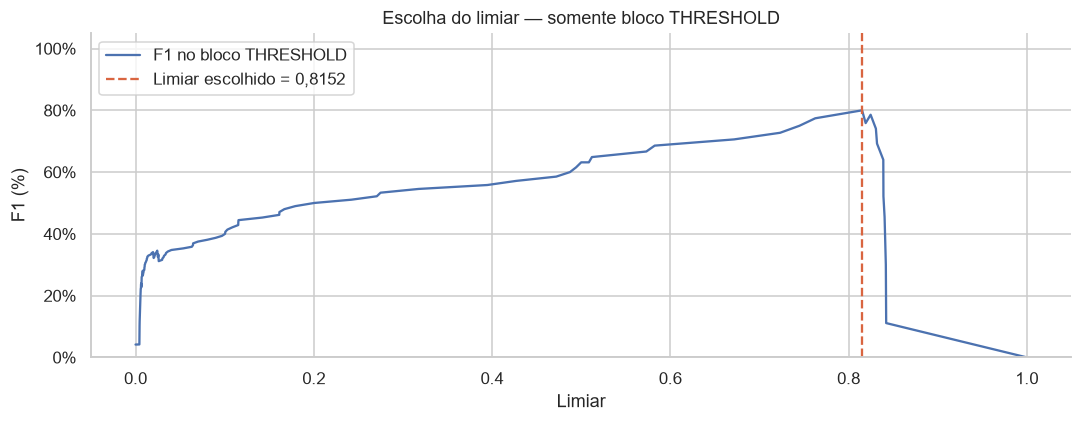

In [5]:
show(f"Limiar escolhido em TRAIN: {manifest['threshold']:.5f}; F1 no bloco de seleção: {manifest['threshold_selection_f1']:.2%}")
print('Política:', manifest['threshold_policy'])
display(readable_table(report.table('threshold_selection')))
report.threshold_selection_figure()

## 6. Etapas na mesma validação, sem seleção posterior

    As três receitas abaixo foram congeladas antes de avaliar este bloco: modelo com
    Optuna/derivadas em limiar 0,5; calibrado em limiar 0,5; calibrado com limiar escolhido.
    Essas métricas não escolhem uma nova versão vencedora. A calibração sigmoid pode
    preservar a ordenação e as áreas, mudando a escala dos scores. Alterar apenas
    o limiar não altera AP/AUPRC dos mesmos scores.

,Receita,Versão,Origem,Observações,Falhas confirmadas,Prevalência de falhas (%),Limiar de alerta,TN: não falhas liberadas,FP: falsos alertas,FN: falhas não detectadas,TP: falhas detectadas,F1 (%),Recall (%),Precision (%),Especificidade (%),Valor preditivo negativo (%),Falsos positivos entre não falhas (%),Falhas não detectadas (%),Taxa de alertas (%),Acurácia (%),Acurácia balanceada (%),AP (score),AUPRC trapezoidal (score),ROC-AUC (score),Brier score,Log Loss,MCC,Kappa
0,XGBoost,"Optuna + derivadas / limiar 0,5",Validação (bloco de TRAIN),1.600,35,"2,19%","0,5000",1.543,22,9,26,"62,65%","74,29%","54,17%","98,59%","99,42%","1,41%","25,71%","3,00%","98,06%","86,44%","0,7624","0,7609","0,9559","0,0149","0,0586","0,6249","0,6168"
1,XGBoost,"Calibrado / limiar 0,5",Validação (bloco de TRAIN),1.600,35,"2,19%","0,5000",1.558,7,12,23,"70,77%","65,71%","76,67%","99,55%","99,24%","0,45%","34,29%","1,88%","98,81%","82,63%","0,7624","0,7609","0,9559","0,0097","0,0439","0,7038","0,7017"
2,XGBoost,Calibrado / limiar ajustado,Validação (bloco de TRAIN),1.600,35,"2,19%","0,8152",1.564,1,16,19,"69,09%","54,29%","95,00%","99,94%","98,99%","0,06%","45,71%","1,25%","98,94%","77,11%","0,7624","0,7609","0,9559","0,0097","0,0439","0,7139","0,6859"


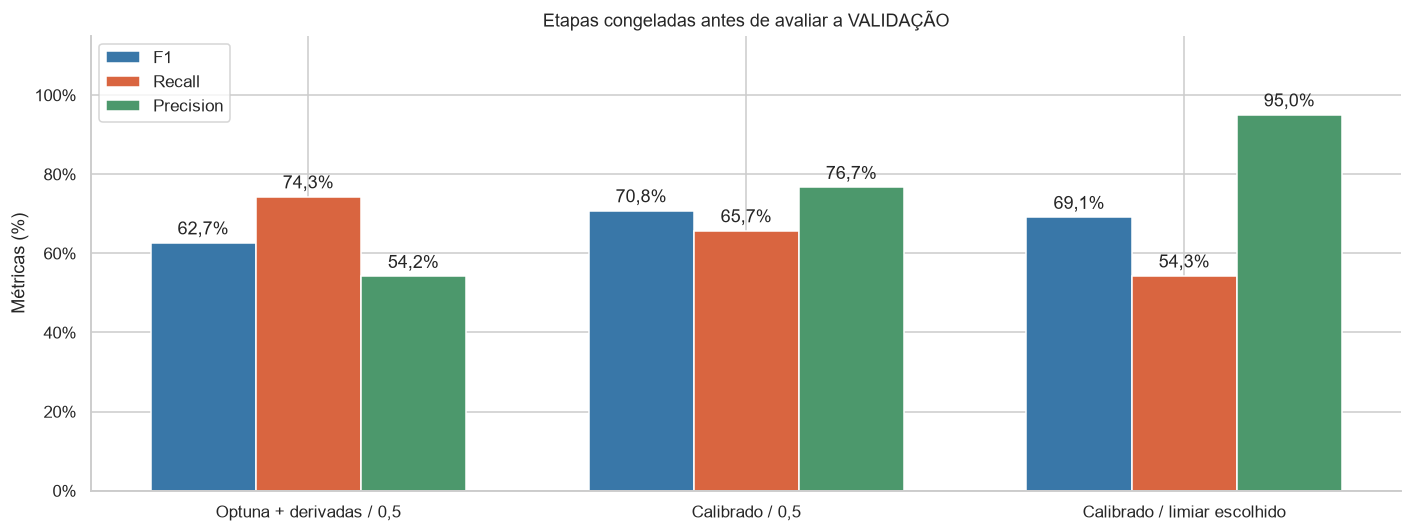

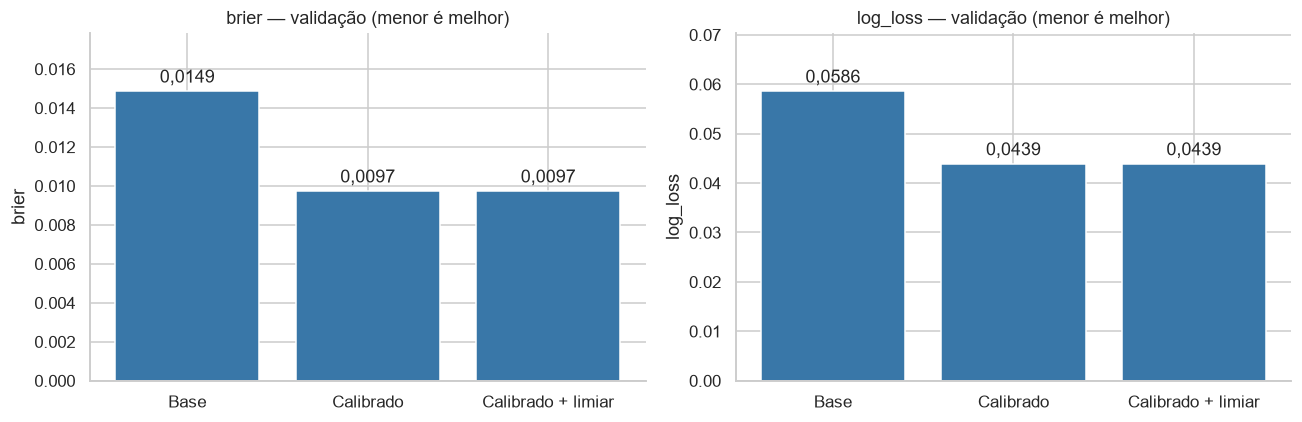

In [6]:
display(readable_table(report.table('stage_metrics')))
report.stage_figures()

## 7. Modelo final versus baseline e matriz

    FIT_RESUBSTITUTION é desempenho no próprio ajuste, sujeito a sobreajuste.
    VALIDATION_TRAIN_BLOCK é o bloco posterior de 1.600. Baseline usa threshold 0,5;
    a receita final usa o limiar aprendido em TRAIN. A tabela identifica ambos.
    Scores de área em 0–1, taxas em %, ausências como Não definido. Não há métricas TEST.

,Receita,Origem,Observações,Falhas confirmadas,Prevalência de falhas (%),Limiar de alerta,TN: não falhas liberadas,FP: falsos alertas,FN: falhas não detectadas,TP: falhas detectadas,F1 (%),Recall (%),Precision (%),Especificidade (%),Valor preditivo negativo (%),Falsos positivos entre não falhas (%),Falhas não detectadas (%),Taxa de alertas (%),Acurácia (%),Acurácia balanceada (%),AP (score),AUPRC trapezoidal (score),ROC-AUC (score),Brier score,Log Loss,MCC,Kappa
0,XGBoost,Treino (reavaliação no ajuste),4.800,221,"4,60%","0,8152",4.579,0,39,182,"90,32%","82,35%","100,00%","100,00%","99,16%","0,00%","17,65%","3,79%","99,19%","91,18%",1,1,1,"0,0016","0,0138","0,9036","0,8990"
1,XGBoost,Validação (bloco de TRAIN),1.600,35,"2,19%","0,8152",1.564,1,16,19,"69,09%","54,29%","95,00%","99,94%","98,99%","0,06%","45,71%","1,25%","98,94%","77,11%","0,7624","0,7609","0,9559","0,0097","0,0439","0,7139","0,6859"
2,Baseline (proporção),Treino (reavaliação no ajuste),4.800,221,"4,60%","0,5000",4.579,0,221,0,"0,00%","0,00%",Não definido,"100,00%","95,40%","0,00%","100,00%","0,00%","95,40%","50,00%","0,0460","0,5230","0,5000","0,0439","0,1867",0,0
3,Baseline (proporção),Validação (bloco de TRAIN),1.600,35,"2,19%","0,5000",1.565,0,35,0,"0,00%","0,00%",Não definido,"100,00%","97,81%","0,00%","100,00%","0,00%","97,81%","50,00%","0,0219","0,5109","0,5000","0,0220","0,1134",0,0


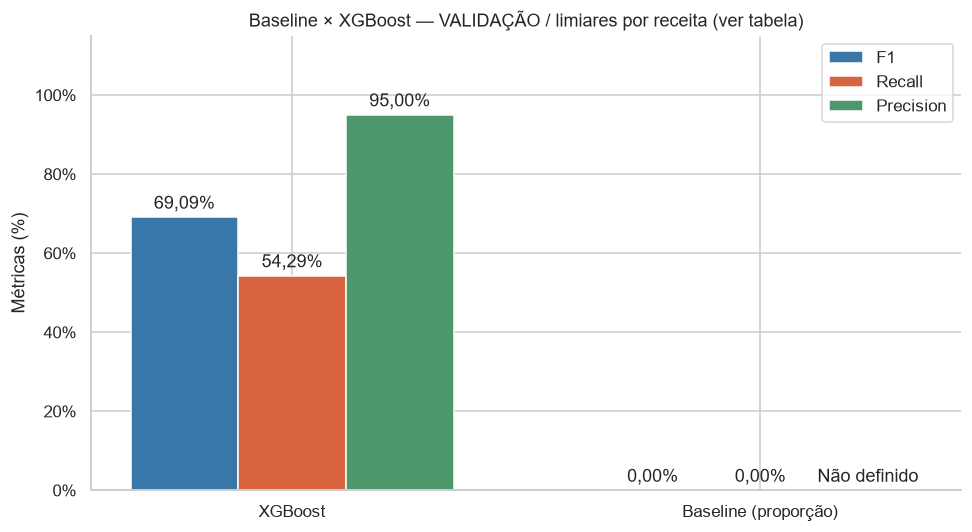

,Classe / média,Precision (%),Recall (%),F1 (%),Observações da classe
0,Sem falha (0),"98,99%","99,94%","99,46%",1.565
1,Falha (1),"95,00%","54,29%","69,09%",35
2,Acurácia,"98,94%","98,94%","98,94%","0,9894"
3,Média macro,"96,99%","77,11%","84,28%",1.600
4,Média ponderada,"98,90%","98,94%","98,80%",1.600


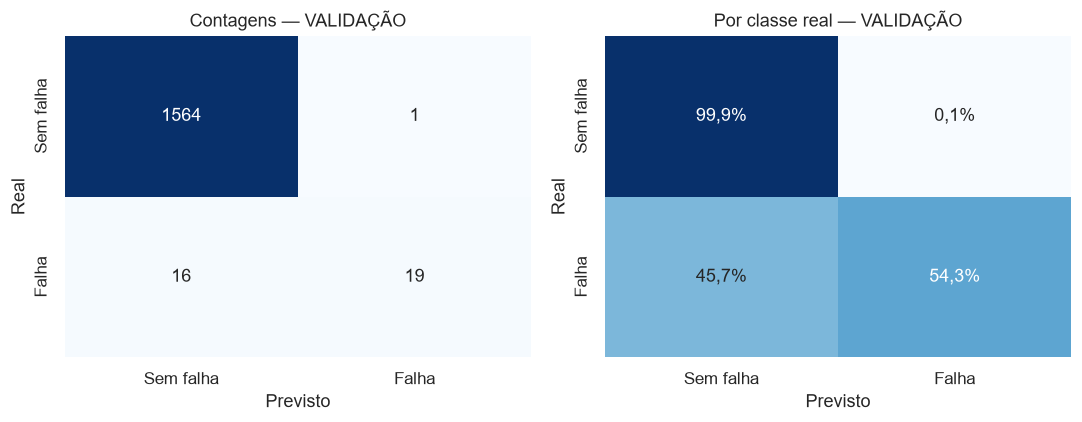

In [7]:
metrics = report.table('model_metrics')
display(readable_table(metrics))
report.comparison()
display(readable_table(report.table('classification_report')))
report.confusion()

## 8. PR/AUPRC/AP, ROC e diagnóstico probabilístico

    AP não é AUPRC trapezoidal. Scores constantes podem ter área trapezoidal alta por
    interpolação de poucos pontos; AP do baseline é a prevalência. Brier/Log Loss e
    curva de confiabilidade complementam a avaliação; não garantem calibração geral.

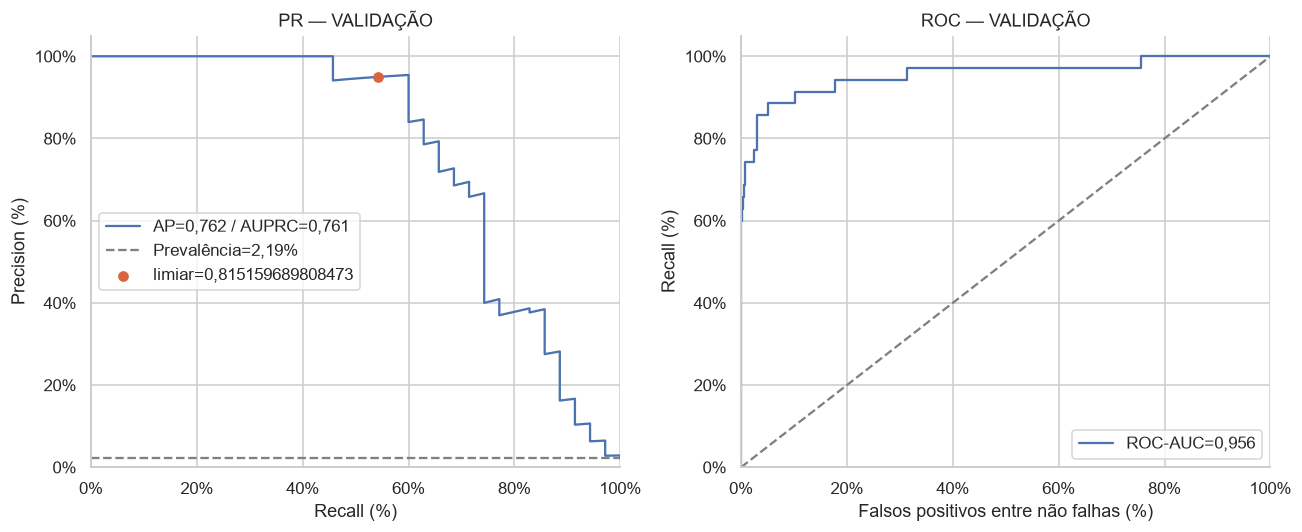

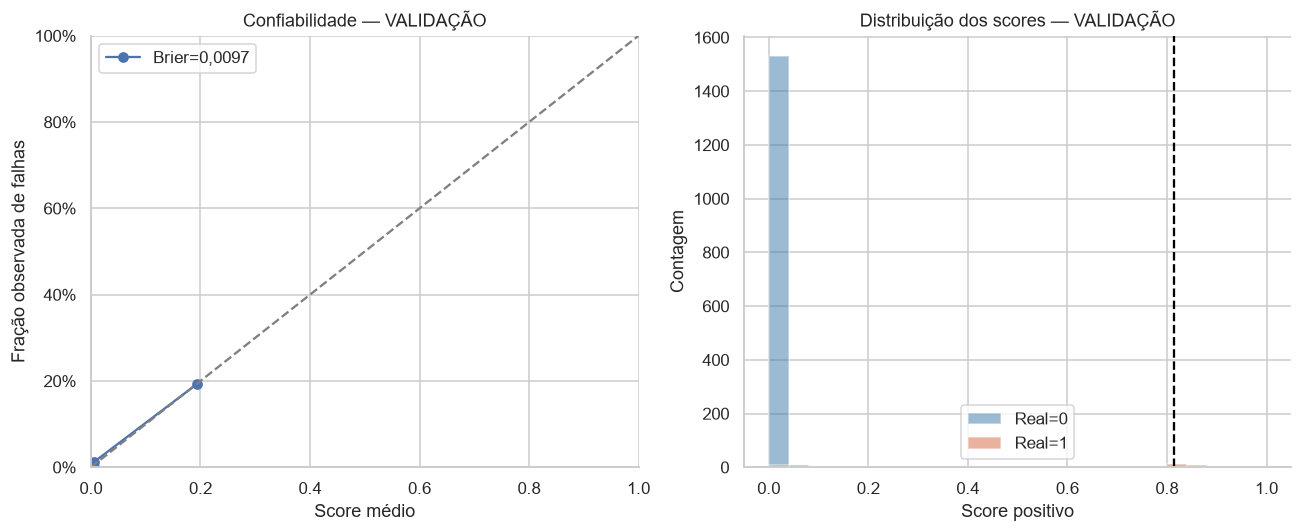

,Score médio,Taxa observada de falhas (%)
0,"0,0043","0,00%"
1,"0,0043","0,00%"
2,"0,0043","0,62%"
3,"0,0043","0,00%"
4,"0,0044","0,00%"
5,"0,0044","0,00%"
6,"0,0045","0,62%"
7,"0,0047","0,00%"
8,"0,0058","1,25%"
9,"0,1945","19,38%"


In [8]:
report.probability_figures()
display(readable_table(report.table('calibration')))

## 9. Sensibilidade na validação — somente diagnóstico

    O limiar destacado já veio do bloco THRESHOLD de TRAIN. A varredura abaixo não
    modifica o pacote nem é usada para escolher novo limiar nesta validação.

,Origem,Observações,Falhas confirmadas,Prevalência de falhas (%),Limiar de alerta,TN: não falhas liberadas,FP: falsos alertas,FN: falhas não detectadas,TP: falhas detectadas,F1 (%),Recall (%),Precision (%),Especificidade (%),Valor preditivo negativo (%),Falsos positivos entre não falhas (%),Falhas não detectadas (%),Taxa de alertas (%),Acurácia (%),Acurácia balanceada (%),AP (score),AUPRC trapezoidal (score),ROC-AUC (score),Brier score,Log Loss,MCC,Kappa
0,Validação (somente diagnóstico),1.600,35,"2,19%","0,0100",1.466,99,4,31,"37,58%","88,57%","23,85%","93,67%","99,73%","6,33%","11,43%","8,12%","93,56%","91,12%","0,7624","0,7609","0,9559","0,0097","0,0439","0,4403","0,3535"
1,Validação (somente diagnóstico),1.600,35,"2,19%","0,0500",1.532,33,9,26,"55,32%","74,29%","44,07%","97,89%","99,42%","2,11%","25,71%","3,69%","97,38%","86,09%","0,7624","0,7609","0,9559","0,0097","0,0439","0,5602","0,5406"
2,Validação (somente diagnóstico),1.600,35,"2,19%","0,1000",1.541,24,9,26,"61,18%","74,29%","52,00%","98,47%","99,42%","1,53%","25,71%","3,12%","97,94%","86,38%","0,7624","0,7609","0,9559","0,0097","0,0439","0,6116","0,6015"
3,Validação (somente diagnóstico),1.600,35,"2,19%","0,2000",1.543,22,9,26,"62,65%","74,29%","54,17%","98,59%","99,42%","1,41%","25,71%","3,00%","98,06%","86,44%","0,7624","0,7609","0,9559","0,0097","0,0439","0,6249","0,6168"
4,Validação (somente diagnóstico),1.600,35,"2,19%","0,3000",1.552,13,10,25,"68,49%","71,43%","65,79%","99,17%","99,36%","0,83%","28,57%","2,38%","98,56%","85,30%","0,7624","0,7609","0,9559","0,0097","0,0439","0,6782","0,6776"
5,Validação (somente diagnóstico),1.600,35,"2,19%","0,4000",1.556,9,12,23,"68,66%","65,71%","71,88%","99,42%","99,23%","0,58%","34,29%","2,00%","98,69%","82,57%","0,7624","0,7609","0,9559","0,0097","0,0439","0,6806","0,6799"
6,Validação (somente diagnóstico),1.600,35,"2,19%","0,5000",1.558,7,12,23,"70,77%","65,71%","76,67%","99,55%","99,24%","0,45%","34,29%","1,88%","98,81%","82,63%","0,7624","0,7609","0,9559","0,0097","0,0439","0,7038","0,7017"
7,Validação (somente diagnóstico),1.600,35,"2,19%","0,7000",1.563,2,14,21,"72,41%","60,00%","91,30%","99,87%","99,11%","0,13%","40,00%","1,44%","99,00%","79,94%","0,7624","0,7609","0,9559","0,0097","0,0439","0,7358","0,7193"
8,Validação (somente diagnóstico),1.600,35,"2,19%","0,8152",1.564,1,16,19,"69,09%","54,29%","95,00%","99,94%","98,99%","0,06%","45,71%","1,25%","98,94%","77,11%","0,7624","0,7609","0,9559","0,0097","0,0439","0,7139","0,6859"
9,Validação (somente diagnóstico),1.600,35,"2,19%","0,9000",1.565,0,35,0,"0,00%","0,00%",Não definido,"100,00%","97,81%","0,00%","100,00%","0,00%","97,81%","50,00%","0,7624","0,7609","0,9559","0,0097","0,0439",0,0


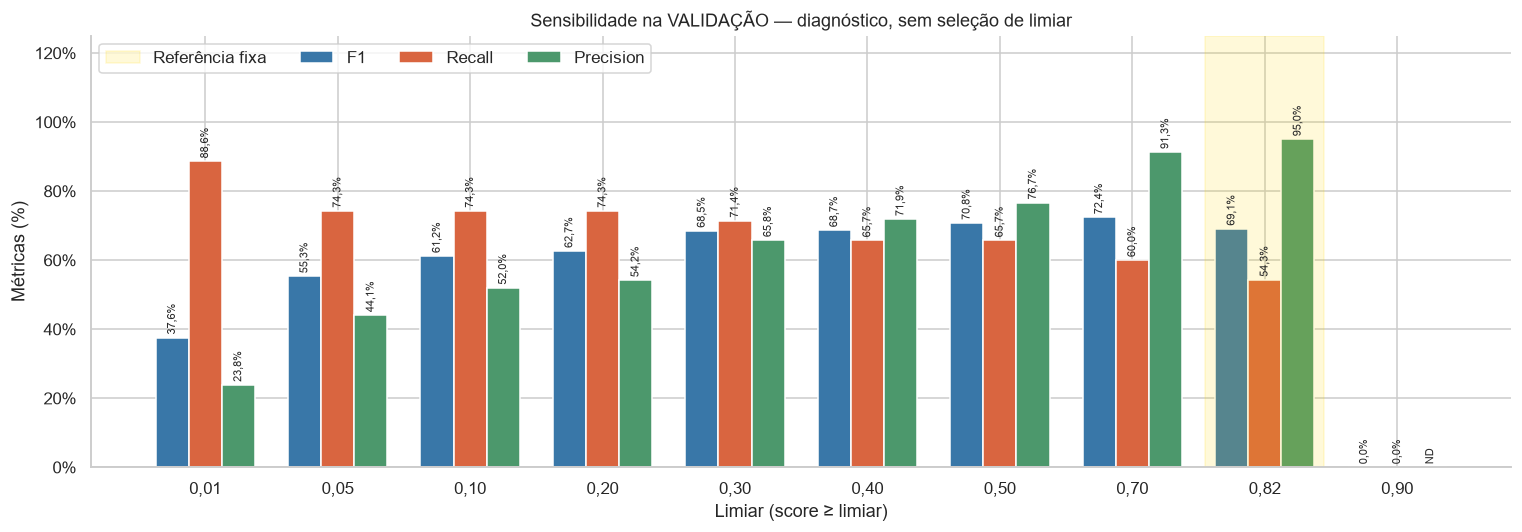

In [9]:
display(readable_table(report.table('threshold_diagnostics')))
report.threshold_figure()

## 10. Associações, importância e erros

    Associação no FIT_SEARCH; permutação na validação como diagnóstico posterior,
    sem seleção de variáveis. Permutar um sensor também afeta as derivadas dele no
    pipeline completo: a importância se refere à entrada original, não isola uma derivada.
    Grupos e faixas incluem suporte; limites são aprendidos no ajuste, sem modificar TEST.

,Variável,Pearson com falha — treino,Spearman com falha — treino,Magnitude da associação — treino,Medida de associação,Queda de AP por permutação — validação,Desvio da permutação (score),Queda de AUPRC por permutação — validação,Desvio da permutação de AUPRC (score)
0,Temperatura do ar [K],"0,1409","0,1365","0,1365",Módulo de Spearman,"0,0368","0,0250","0,0377","0,0251"
1,Temperatura do processo [K],"0,1081","0,1090","0,1090",Módulo de Spearman,"0,0255","0,0257","0,0263","0,0261"
2,Velocidade de rotação [rpm],"-0,0540","-0,2098","0,2098",Módulo de Spearman,"0,2511","0,0438","0,2552","0,0445"
3,Torque [Nm],"0,2095","0,2015","0,2015",Módulo de Spearman,"0,6989","0,0219","0,7036","0,0220"
4,Desgaste da ferramenta [min],"0,0896","0,0867","0,0867",Módulo de Spearman,"0,3989","0,0488","0,4043","0,0498"
5,Tipo,Não definido,Não definido,"0,0311",V de Cramér,"0,0616","0,0218","0,0629","0,0219"


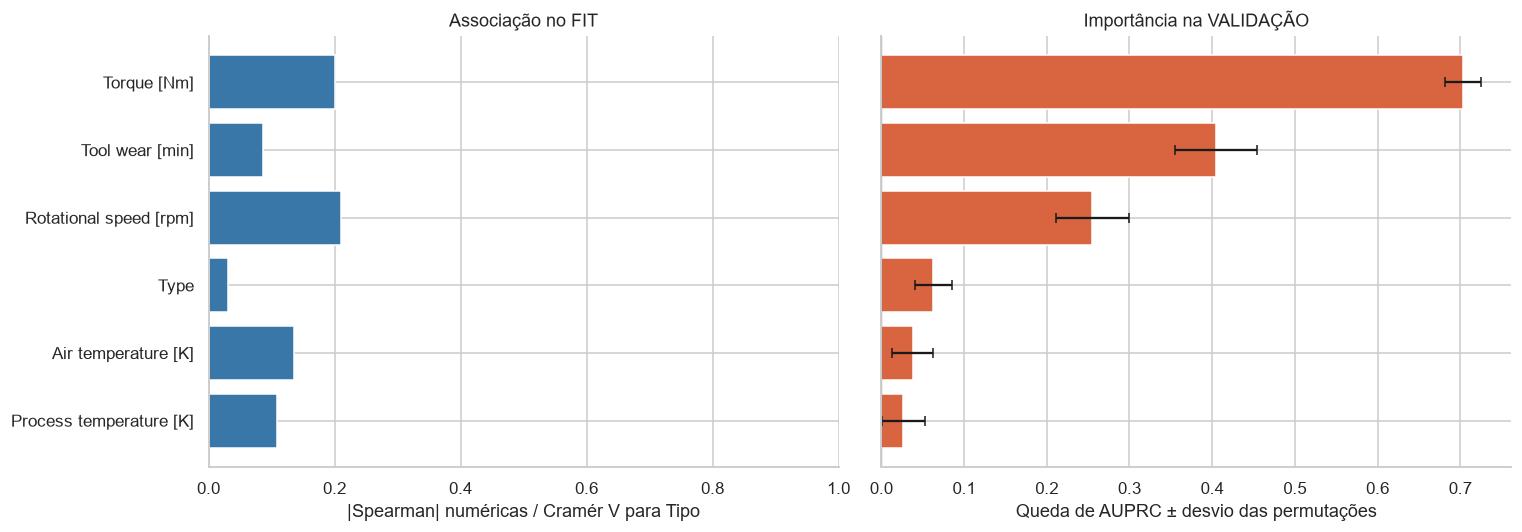

,Variável de agrupamento,Faixa / categoria,Observações,Falhas confirmadas,Prevalência de falhas (%),Limiar de alerta,TN: não falhas liberadas,FP: falsos alertas,FN: falhas não detectadas,TP: falhas detectadas,F1 (%),Recall (%),Precision (%),Especificidade (%),Valor preditivo negativo (%),Falsos positivos entre não falhas (%),Falhas não detectadas (%),Taxa de alertas (%),Acurácia (%),Acurácia balanceada (%),AP (score),AUPRC trapezoidal (score),ROC-AUC (score),Brier score,Log Loss,MCC,Kappa
0,Tipo,H,147,1,"0,68%","0,8152",146,0,1,0,"0,00%","0,00%",Não definido,"100,00%","99,32%","0,00%","100,00%","0,00%","99,32%","50,00%","0,3333","0,1667","0,9863","0,0068","0,0314",0,0
1,Tipo,L,968,24,"2,48%","0,8152",943,1,10,14,"71,79%","58,33%","93,33%","99,89%","98,95%","0,11%","41,67%","1,55%","98,86%","79,11%","0,8228","0,8214","0,9508","0,0085","0,0401","0,7330","0,7125"
2,Tipo,M,485,10,"2,06%","0,8152",475,0,5,5,"66,67%","50,00%","100,00%","100,00%","98,96%","0,00%","50,00%","1,03%","98,97%","75,00%","0,6729","0,6658","0,9714","0,0131","0,0553","0,7034","0,6620"


,Variável de agrupamento,Faixa / categoria,Observações,Falhas confirmadas,Prevalência de falhas (%),Limiar de alerta,TN: não falhas liberadas,FP: falsos alertas,FN: falhas não detectadas,TP: falhas detectadas,F1 (%),Recall (%),Precision (%),Especificidade (%),Valor preditivo negativo (%),Falsos positivos entre não falhas (%),Falhas não detectadas (%),Taxa de alertas (%),Acurácia (%),Acurácia balanceada (%),AP (score),AUPRC trapezoidal (score),ROC-AUC (score),Brier score,Log Loss,MCC,Kappa
0,Temperatura do ar [K],"(298.8, 300.1]",307,3,"0,98%","0,8152",304,0,1,2,"80,00%","66,67%","100,00%","100,00%","99,67%","0,00%","33,33%","0,65%","99,67%","83,33%","0,7436","0,7329","0,9890","0,0063","0,0279","0,8152","0,7984"
1,Temperatura do ar [K],"(300.1, 302.0]",1.293,32,"2,47%","0,8152",1.260,1,15,17,"68,00%","53,12%","94,44%","99,92%","98,82%","0,08%","46,88%","1,39%","98,76%","76,52%","0,7686","0,7670","0,9511","0,0106","0,0477","0,7034","0,6742"
2,Temperatura do processo [K],"(309.0, 309.6]",17,0,"0,00%","0,8152",17,0,0,0,"0,00%",Não definido,Não definido,"100,00%","100,00%","0,00%",Não definido,"0,00%","100,00%",Não definido,Não definido,Não definido,Não definido,"0,0000","0,0043",Não definido,Não definido
3,Temperatura do processo [K],"(309.6, 310.6]",630,10,"1,59%","0,8152",620,0,4,6,"75,00%","60,00%","100,00%","100,00%","99,36%","0,00%","40,00%","0,95%","99,37%","80,00%","0,6701","0,6666","0,9079","0,0105","0,0465","0,7721","0,7470"
4,Temperatura do processo [K],"(310.6, inf]",953,25,"2,62%","0,8152",927,1,12,13,"66,67%","52,00%","92,86%","99,89%","98,72%","0,11%","48,00%","1,47%","98,64%","75,95%","0,8155","0,8134","0,9757","0,0094","0,0429","0,6894","0,6603"
5,Velocidade de rotação [rpm],"(-inf, 1405.0]",329,21,"6,38%","0,8152",308,0,8,13,"76,47%","61,90%","100,00%","100,00%","97,47%","0,00%","38,10%","3,95%","97,57%","80,95%","0,9281","0,9273","0,9825","0,0150","0,0662","0,7768","0,7526"
6,Velocidade de rotação [rpm],"(1405.0, 1469.0]",298,4,"1,34%","0,8152",293,1,2,2,"57,14%","50,00%","66,67%","99,66%","99,32%","0,34%","50,00%","1,01%","98,99%","74,83%","0,6399","0,6047","0,9779","0,0118","0,0451","0,5724","0,5664"
7,Velocidade de rotação [rpm],"(1469.0, 1543.0]",371,1,"0,27%","0,8152",370,0,1,0,"0,00%","0,00%",Não definido,"100,00%","99,73%","0,00%","100,00%","0,00%","99,73%","50,00%","0,0222","0,0111","0,8811","0,0027","0,0191",0,0
8,Velocidade de rotação [rpm],"(1543.0, 1642.0]",273,0,"0,00%","0,8152",273,0,0,0,"0,00%",Não definido,Não definido,"100,00%","100,00%","0,00%",Não definido,"0,00%","100,00%",Não definido,Não definido,Não definido,Não definido,"0,0001","0,0051",Não definido,Não definido
9,Velocidade de rotação [rpm],"(1642.0, inf]",329,9,"2,74%","0,8152",320,0,5,4,"61,54%","44,44%","100,00%","100,00%","98,46%","0,00%","55,56%","1,22%","98,48%","72,22%","0,6104","0,6018","0,8847","0,0186","0,0808","0,6615","0,6088"


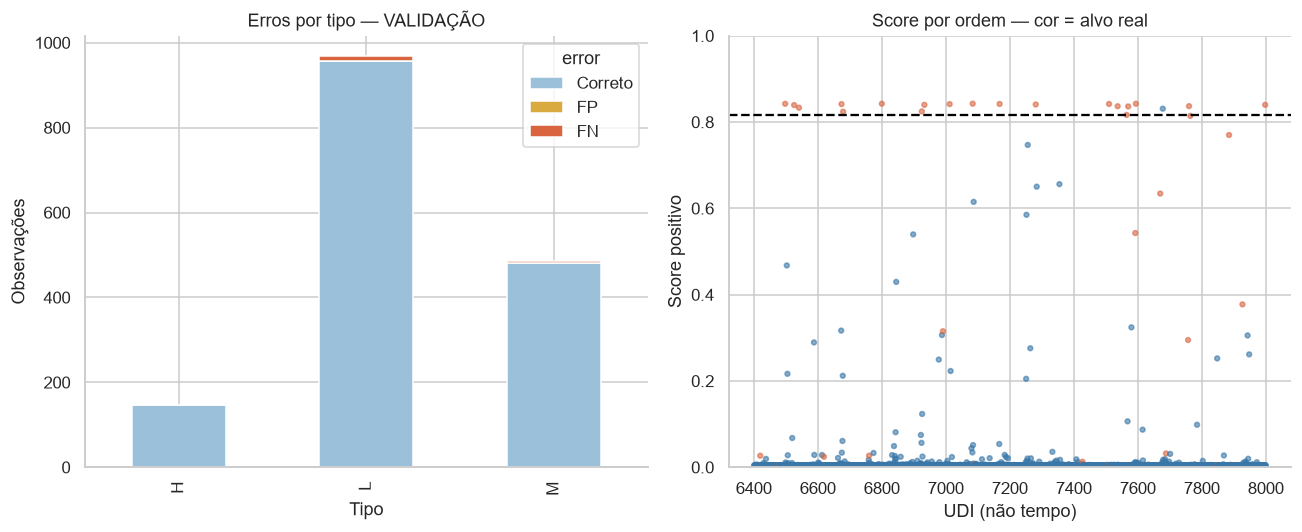

In [10]:
display(readable_table(report.table('feature_association_importance')))
report.feature_figure()
display(readable_table(report.table('segment_type')))
display(readable_table(report.table('segment_numeric')))
report.error_figure()

## 11. Comparação com a rodada anterior

    Mesmas observações e alvos de validação, CSV original preservado. Busca, tamanho
    do ajuste, features, calibração e limiar mudaram juntos: não atribuir uma diferença
    somente ao Optuna ou à engenharia. As etapas não foram escolhidas pela validação.
    O pacote anterior continua disponível; a versão atual não é confirmação independente.

,Versão,Limiar de alerta,AUPRC trapezoidal (score),AP (score),F1 (%),Recall (%),Precision (%),Brier score,Log Loss,FP: falsos alertas,FN: falhas não detectadas
0,Anterior,"0,5000","0,4917","0,5103","50,60%","60,00%","43,75%","0,0213","0,0913",27,14
1,Atual,"0,8152","0,7609","0,7624","69,09%","54,29%","95,00%","0,0097","0,0439",1,16


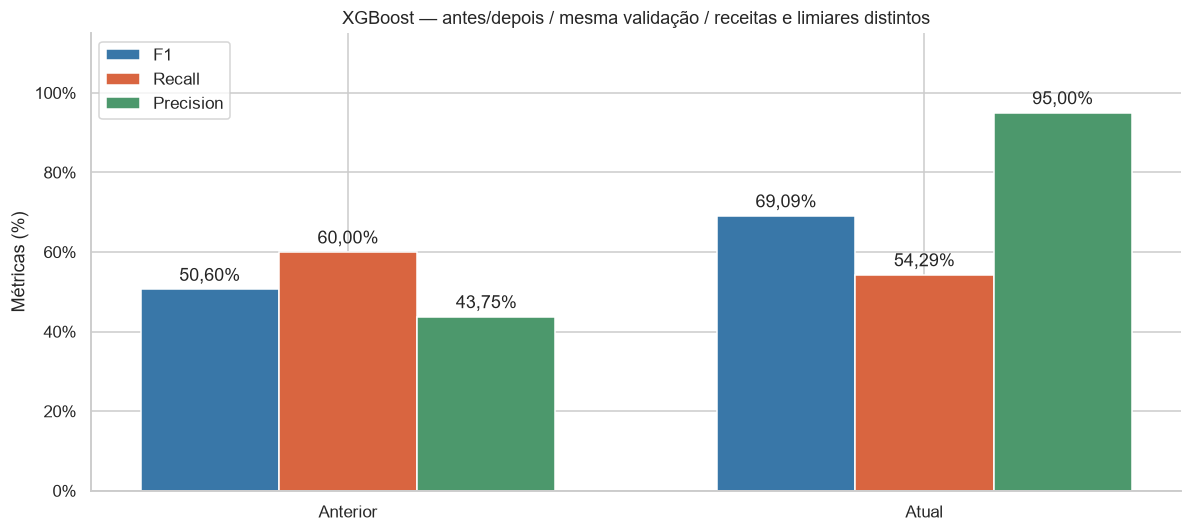

F1: 50,60% → 69,09%; Recall: 60,00% → 54,29%; Precision: 43,75% → 95,00%. AP: 0,5103 → 0,7624; AUPRC: 0,4917 → 0,7609.

In [11]:
comparison = report.table('previous_comparison')
display(readable_table(comparison[['version','threshold','auprc','ap','f1','recall','precision','brier','log_loss','fp','fn']]))
report.previous_figure()
before, after = comparison.iloc[0], comparison.iloc[-1]
show(f"F1: {before.f1:.2%} → {after.f1:.2%}; Recall: {before.recall:.2%} → {after.recall:.2%}; "
     f"Precision: {before.precision:.2%} → {after.precision:.2%}. "
     f"AP: {before.ap:.4f} → {after.ap:.4f}; AUPRC: {before.auprc:.4f} → {after.auprc:.4f}.")

## 12. Artefato e proveniência

    O pacote inclui derivadas, preparação, SMOTENC, classificador, calibrador e limiar.
    Carregar apenas joblib de origem confiável. Inferência não reamostra ou reajusta.
    Base treinada em 4.800, calibrador em 800, limiar em 800; não há refit posterior.

In [12]:
print('Pipeline:', manifest['model_path'])
print('SHA256:', manifest['model_sha256'])
print('Equivalência após serialização:', manifest['serialization_verified'])
print('Tabelas:', report.tables.relative_to(ROOT))
print('Figuras:', report.figures.relative_to(ROOT))
display(manifest['limitations'])

Pipeline: models/train_xgboost_20261101T001759Z_4c8d9ea9/pipeline.joblib
SHA256: 3fabae724a15cbd8d4422f02a8a840187048347e352fe9a79da628b71a454797
Equivalência após serialização: True
Tabelas: reports\metrics\train_xgboost_20261101T001759Z_4c8d9ea9
Figuras: reports\figures\train_xgboost_20261101T001759Z_4c8d9ea9


['Reused development validation, not independent confirmation',
 'Base model fit on 4800 rather than previous 6400; CV not directly comparable',
 'Only 27 calibration positives and 17 threshold positives',
 'Sigmoid fit does not prove calibration on unseen data',
 'Derived synthetic features may not satisfy exact physical identities',
 'UDI not verified time; gap zero; no TEST evaluation']